In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.integrate import ode, odeint, solve_ivp, solve_bvp
from scipy import optimize as opt

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})

def runge_kutta_4(f, t, y0, *args, **kwargs):
    """
    Metoda Runge-Kutta 4. reda za reševanje diferencialne enačbe: y' = f(t, y)
    
    :param f: funkcija, ki jo kličemo s parametroma t in y in vrne 
              vrednost prvega odvoda
    :param t: ekvidistanten časovni vektor oz. neodvisna spremenljivka
    :param y0: začetna vrednost
    :param args: dodatni argumenti funkcije f (brezimenski)
    :param kwargs: dodatni argumenti funkcije f (poimenovani)
    :return y: funkcijske vrednosti.
    """
    def RK4(f, t, y, *args, **kwargs):
        k0 = h*f(t, y, *args, **kwargs)
        k1 = h*f(t + h/2.0, y + k0/2.0, *args, **kwargs)
        k2 = h*f(t + h/2.0, y + k1/2.0, *args, **kwargs)
        k3 = h*f(t + h, y + k2, *args, **kwargs)
        return (k0 + 2.0*k1 + 2.0*k2 + k3)/6.0
    
    y = np.zeros(shape=(len(t),len(y0)))
    y[0] = y0
    h = t[1]-t[0]

    for i, ti in enumerate(t[1:]):
        y[i+1] = y[i] + RK4(f, ti, y[i], *args, **kwargs)
        
    return y.T

In [2]:
def DE(x,y, e):
    R,z = y
    dRdx = z
    dzdx = (-2/x + (l*(l+1))/x**2 - e) * R
    return np.array([dRdx, dzdx])
# def analiticno_zasuk(x):
#     return 2*np.exp(-x)
# def analiticno_y(x):
#     return x*(1-x/2)/2**0.5 * np.exp(-x/2)
def R10(x):
    return x*np.e**(-x)
def R20(x):
    return x*(1-x/2)*np.e**(-x/2)
def R21(x):
    return x**2*np.e**(-x/2)

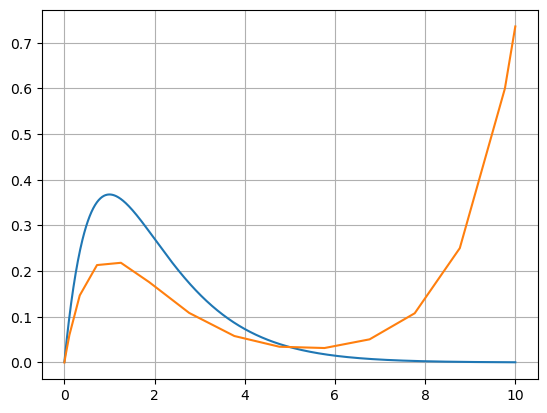

In [3]:
l=0
n=1000 #št. korakov
x_min,x_max = 0.001, 10
dx = (x_max-x_min)/n
x = np.linspace(x_min,x_max,n)

y_zp = [0, 0.6] #začetna lega, naklon
e = -1. #energija - shooting parameter

y, dydx = runge_kutta_4(DE, x, np.array(y_zp), e=e) #pobezlja
res = solve_ivp(DE, t_span=(x_min,x_max), y0=np.array(y_zp), method='RK45', max_step=1, args=(e,)) #auto dx
#res = solve_ivp(DE, t_span=(x_min,x_max), y0=np.array(y_zp), t_eval=x, method='RK45',args=(e,))
y1, dy1dx = res.y
x1 = res.t

plt.plot(x, R10(x))
#plt.plot(x,y)
plt.plot(x1,y1)
plt.grid()

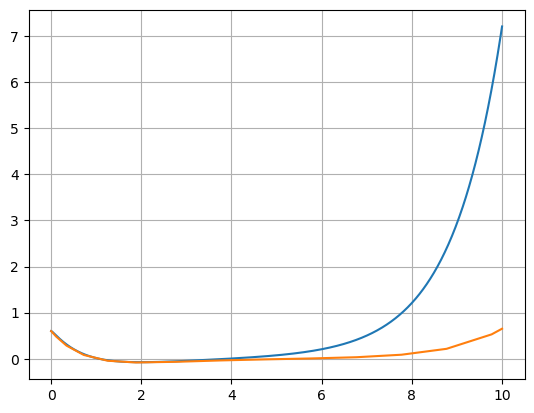

In [4]:
#zasuki
plt.plot(x,dydx)
plt.plot(x1,dy1dx)
plt.grid()

In [5]:
def napaka_energija(e):
    #y_zp = np.array([y0, zasuk_0])
    e = e[0]
    y, dydx = solve_ivp(DE, t_span=(x_min,x_max), y0=y_zp, t_eval=x, method='RK45', args=(e,)).y
    return y[-1] + dydx[-1]

-1.000020246877049

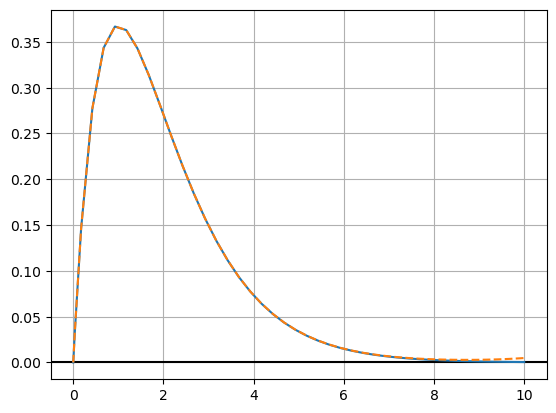

In [6]:
# optimize
l=0
n=1000 #št. korakov
x_min,x_max = 1e-10, 10
dx = (x_max-x_min)/n
x = np.linspace(x_min,x_max,n)

y0 = 0 #zač lega
zasuk_0 = 1 # ZP
e0 = -1 #energija ZP guess
y_zp = np.array([y0, zasuk_0])

sol = opt.root(napaka_energija, x0=e0, method='lm', tol=10**-10)
e = sol.x[0]

#y, dydx = runge_kutta_4(DE, x, y_zp, e=e) #pobezlja
res = solve_ivp(DE, t_span=(x_min,x_max), y0=y_zp, method='RK45', max_step=0.25, args=(e,)) #auto dx
#res = solve_ivp(DE, t_span=(x_min,x_max), y0=y_zp, t_eval=x, method='RK45', args=(e,))
y1,y1_ = res.y
x1 = res.t

y_analiticno = R10(x1)
err = np.sum(np.abs(y_analiticno - y1))

plt.axhline(0,color='k')
plt.plot(x1,y_analiticno,'-') 
#plt.plot(x,y)
plt.plot(x1,y1,'--')
plt.grid()
e

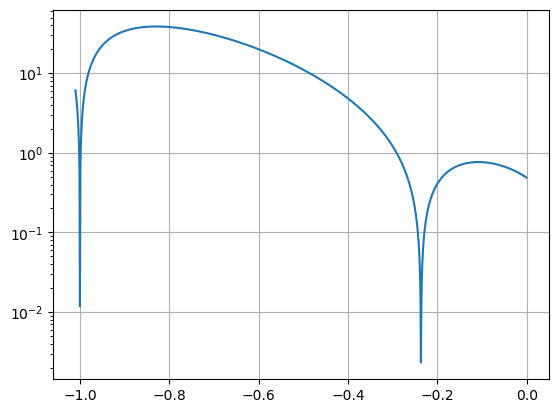

In [7]:
N = []
e_list = np.arange(-1.01, -0.001, 0.001)
for e in e_list:
    n_i = napaka_energija([e])
    N.append(n_i)
plt.plot(e_list, np.abs(N))
plt.grid()
plt.yscale('log')

# numerov

In [45]:
def numerov(k, x, y0):
    '''reševanje DE oblike [d²/dx² + k²(x)] y(x) = 0,
    podana funkcija k(x) naj bo že kvadrirana'''
    h = x[1]-x[0]
    y = np.zeros_like(x)
    y[0] = y0[0]
    y[1] = y[0] + h*y0[1] #ZP?
    for i in range(1,len(x)-1):
        y[i+1] = (2*(1-h**2*5/12*k(x[i]))*y[i] - (1-h**2/12*k(x[i-1]))*y[i-1]) / (1+h**2/12*k(x[i+1]))
    return y
def k(x):
    return 2/x - l*(l+1)/x + e

-0.9960849208329985

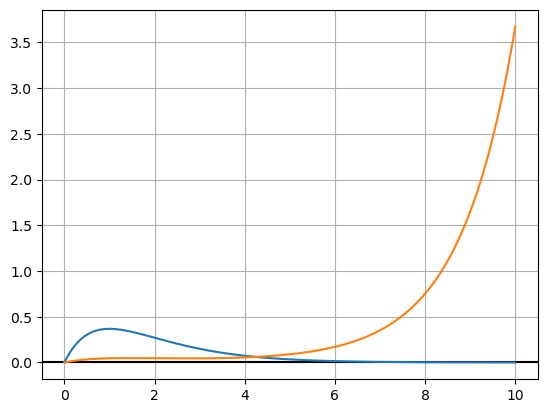

In [46]:
# numerov
l=0
n=1000 #št. korakov
x_min,x_max = 0.001, 10
dx = (x_max-x_min)/n
x = np.linspace(x_min,x_max,n)

y0 = 0 #zač lega
zasuk_0 = 0.1 # ZP
e0 = -1 #energija ZP guess
y_zp = np.array([y0, zasuk_0])

sol = opt.root(napaka_energija, x0=e0, method='lm', tol=10**-10)
e = sol.x[0]

R = numerov(k, x, y_zp)
analiticno = R10(x)
err = np.sum(np.abs(analiticno - R))

plt.axhline(0,color='k')
plt.plot(x,analiticno)
plt.plot(x, R)
plt.grid()
e